# NASA Kepler Objects of Interest — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/), Kepler Objects of Interest *cumulative* table ([column definitions](https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html)), retrieved through the archive's TAP service. This research has made use of the NASA Exoplanet Archive, which is operated by the California Institute of Technology under contract with NASA.

The Kepler space telescope (2009–2013) monitored the brightness of about 150,000 stars. A planet passing in front of its star causes a small, periodic dip in brightness, a *transit*. Signals that looked like transits became **Kepler Objects of Interest (KOIs)**. Many turned out to be something else, such as eclipsing binary stars, light from a background star, or instrument noise. Each KOI has a disposition: **CONFIRMED** planet, **FALSE POSITIVE**, or **CANDIDATE** (not yet resolved).

Each row is one KOI. One star can host several KOIs. The numbers are **derived from fits to the light curves**, not raw brightness measurements. The catalog is a selected set of transit-like signals, not a random sample of stars or planets. It is still updated, so counts depend on the download date.

| Column | Description |
|---|---|
| `kepid` | Kepler ID of the host star (shared by all KOIs on that star) |
| `kepoi_name` | KOI identifier, e.g. `K00752.01` (star number . signal number) |
| `koi_disposition` | `CONFIRMED`, `FALSE POSITIVE`, or `CANDIDATE` |
| `koi_period` | Orbital period (days) |
| `koi_depth` | Transit depth: fractional dip in brightness (parts per million) |
| `koi_duration` | Transit duration (hours) |
| `koi_prad` | Planet radius implied by the fit (Earth radii); computed from the depth and the star's radius, so very large values usually mean the signal is not a planet |
| `koi_steff` | Host star effective temperature (K) |
| `koi_kepmag` | Host star brightness in the Kepler band (magnitude; **larger means fainter**) |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the data (internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
CSV_PATH = DATA / 'kepler_koi_cumulative.csv'
COLUMNS = ['kepid', 'kepoi_name', 'koi_disposition', 'koi_period', 'koi_depth',
           'koi_duration', 'koi_prad', 'koi_steff', 'koi_kepmag']
URL = 'https://exoplanetarchive.ipac.caltech.edu/TAP/sync'
QUERY = 'SELECT ' + ', '.join(COLUMNS) + ' FROM cumulative'

if not CSV_PATH.is_file():
    r = requests.get(URL, params={'query': QUERY, 'format': 'csv'}, timeout=120)
    r.raise_for_status()
    CSV_PATH.write_bytes(r.content)

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(9564, 9)


,kepid,kepoi_name,koi_disposition,koi_period,koi_depth,koi_duration,koi_prad,koi_steff,koi_kepmag
0,10797460,K00752.01,CONFIRMED,9.488036,615.8,2.95750,2.26,5455.0,15.347
1,10797460,K00752.02,CONFIRMED,54.418383,874.8,4.50700,2.83,5455.0,15.347
2,10811496,K00753.01,CANDIDATE,19.899140,10829.0,1.78220,14.60,5853.0,15.436
3,10848459,K00754.01,FALSE POSITIVE,1.736952,8079.2,2.40641,33.46,5805.0,15.597
4,10854555,K00755.01,CONFIRMED,2.525592,603.3,1.65450,2.75,6031.0,15.509


In [2]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
kepid,9564.0,NaN,NaN,NaN,7690628.327373,2653459.080974,757450.0,5556034.25,7906892.0,9873066.5,12935144.0
kepoi_name,9564,9564,K00752.01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
koi_disposition,9564,3,FALSE POSITIVE,4839,NaN,NaN,NaN,NaN,NaN,NaN,NaN
koi_period,9564.0,NaN,NaN,NaN,75.671358,1334.744046,0.241843,2.733684,9.752831,40.715178,129995.7784
koi_depth,9201.0,NaN,NaN,NaN,23791.343984,82242.684708,0.0,159.9,421.1,1473.4,1541400.0
koi_duration,9564.0,NaN,NaN,NaN,5.621606,6.471554,0.052,2.43775,3.7926,6.2765,138.54
koi_prad,9201.0,NaN,NaN,NaN,102.891778,3077.639126,0.08,1.4,2.39,14.93,200346.0
koi_steff,9201.0,NaN,NaN,NaN,5706.82328,796.857947,2661.0,5310.0,5767.0,6112.0,15896.0
koi_kepmag,9563.0,NaN,NaN,NaN,14.264606,1.385448,6.966,13.44,14.52,15.322,20.003


In [3]:
df.isna().sum()

kepid                0
kepoi_name           0
koi_disposition      0
koi_period           0
koi_depth          363
koi_duration         0
koi_prad           363
koi_steff          363
koi_kepmag           1
dtype: int64

## 2. A first look

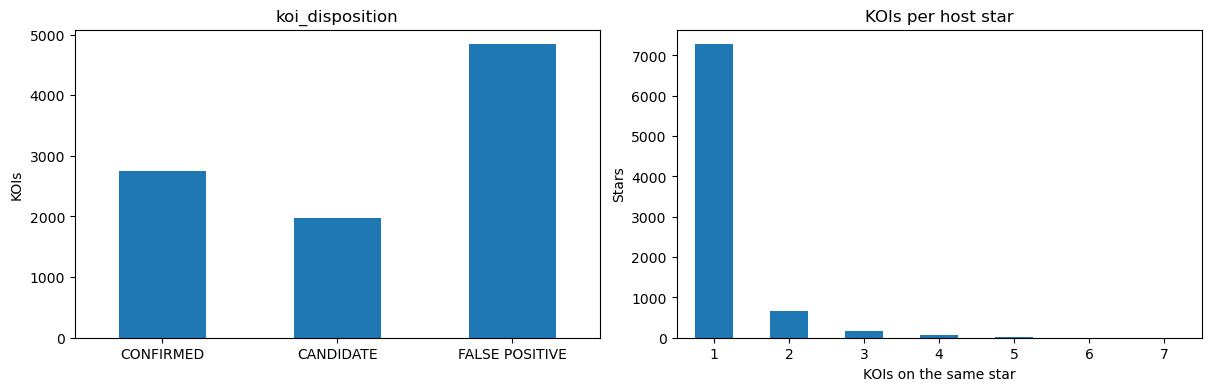

In [4]:
ORDER = ['CONFIRMED', 'CANDIDATE', 'FALSE POSITIVE']
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
df['koi_disposition'].value_counts().reindex(ORDER).plot.bar(ax=axs[0], rot=0)
axs[0].set(xlabel='', ylabel='KOIs', title='koi_disposition')
per_star = df.groupby('kepid').size().value_counts().sort_index()
per_star.plot.bar(ax=axs[1], rot=0)
axs[1].set(xlabel='KOIs on the same star', ylabel='Stars', title='KOIs per host star')
plt.show()

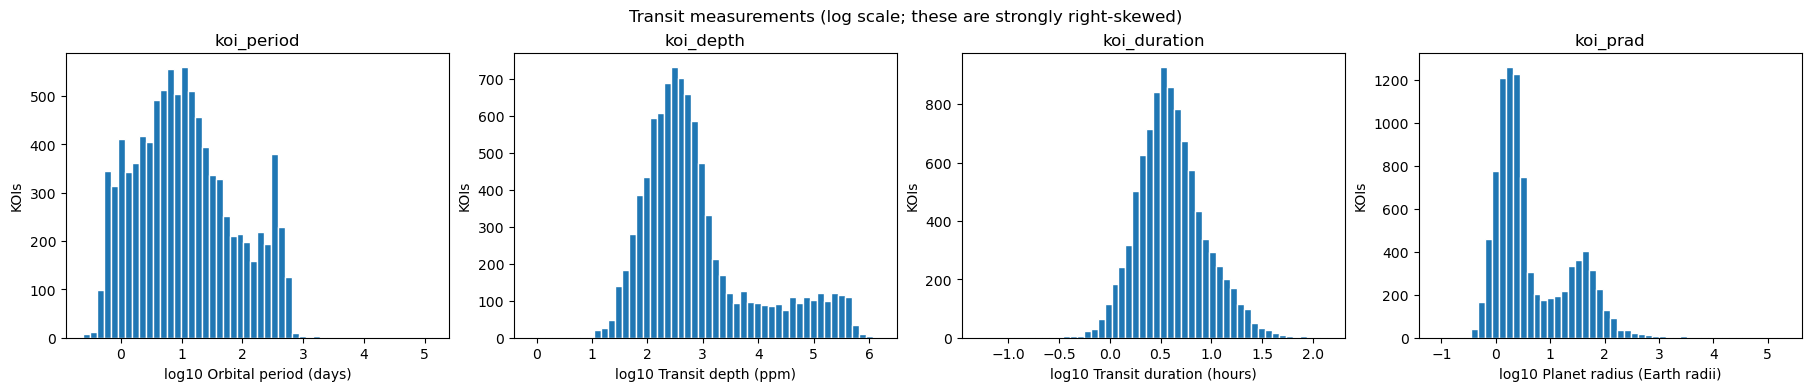

In [5]:
cols = [('koi_period', 'Orbital period (days)'), ('koi_depth', 'Transit depth (ppm)'),
        ('koi_duration', 'Transit duration (hours)'), ('koi_prad', 'Planet radius (Earth radii)')]
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8), constrained_layout=True)
for ax, (col, label) in zip(axs, cols):
    x = df[col][df[col] > 0]
    ax.hist(np.log10(x), bins=50, edgecolor='white')
    ax.set(xlabel=f'log10 {label}', ylabel='KOIs', title=col)
fig.suptitle('Transit measurements (log scale; these are strongly right-skewed)')
plt.show()

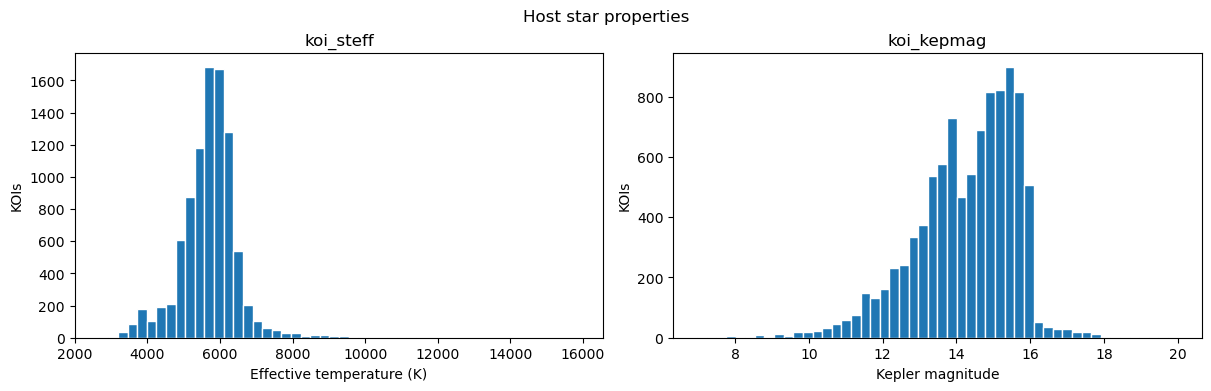

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for ax, (col, label) in zip(axs, [('koi_steff', 'Effective temperature (K)'),
                                  ('koi_kepmag', 'Kepler magnitude')]):
    ax.hist(df[col].dropna(), bins=50, edgecolor='white')
    ax.set(xlabel=label, ylabel='KOIs', title=col)
fig.suptitle('Host star properties')
plt.show()

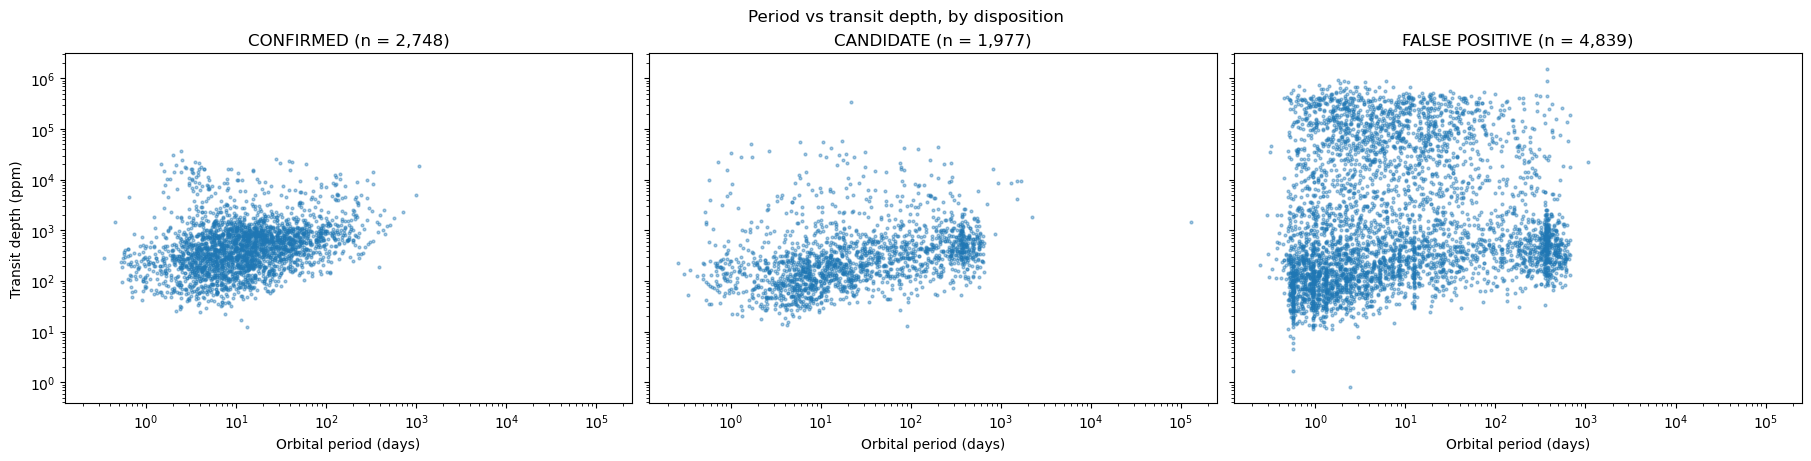

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5), sharex=True, sharey=True, constrained_layout=True)
for ax, label in zip(axs, ORDER):
    g = df[df['koi_disposition'] == label]
    ax.scatter(g['koi_period'], g['koi_depth'], s=4, alpha=0.4)
    ax.set(xscale='log', yscale='log', xlabel='Orbital period (days)', title=f'{label} (n = {len(g):,})')
axs[0].set_ylabel('Transit depth (ppm)')
fig.suptitle('Period vs transit depth, by disposition')
plt.show()

/tmp/ipykernel_1921982/2541242765.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=ORDER, vert=False)


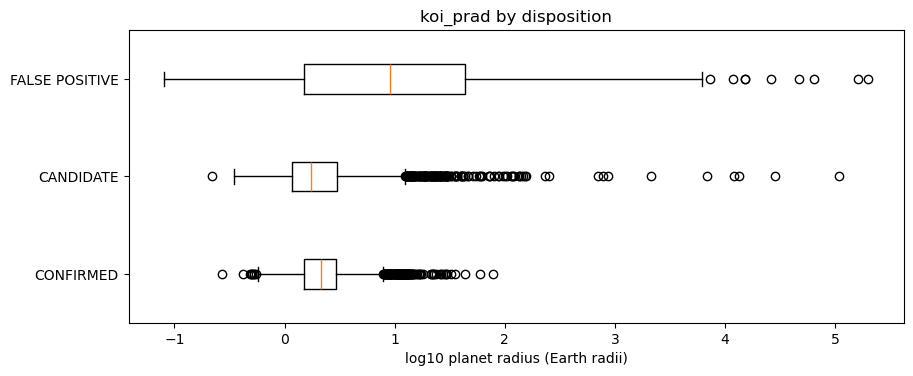

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
data = [np.log10(df.loc[(df['koi_disposition'] == d) & (df['koi_prad'] > 0), 'koi_prad']) for d in ORDER]
ax.boxplot(data, labels=ORDER, vert=False)
ax.set(xlabel='log10 planet radius (Earth radii)', title='koi_prad by disposition')
plt.show()

## 3. Your exploration
Add your own analysis below.